# Phase C: training-season exploration
Scratch work for section 4. Uses only 2020-2024 outcomes, plus 2019 lag history.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROCESSED_DIR = ROOT / "data" / "processed"

# Same values as the main notebook's config cell. Change them there, not here.
SEED = 363
POSITIONS = ["QB", "RB", "WR", "TE"]
TRAIN_SEASONS = list(range(2020, 2025))
TEST_SEASON = 2025
TARGET = "fantasy_points_ppr"
CV_VALID_SEASONS = [2022, 2023, 2024]
TOP_N = 12

## Shared data
`features` has one row per player-week (2020-2025) with the target. `FEATURE_FAMILIES` lists the only columns that may be used as model inputs. `train` drops 2025, which is only for the final test (Phase H).

In [2]:
features = pd.read_parquet(PROCESSED_DIR / "features.parquet")
FEATURE_FAMILIES = json.loads((PROCESSED_DIR / "feature_families.json").read_text())
ALL_FEATURES = [c for cols in FEATURE_FAMILIES.values() for c in cols]

train = features[features["season"].isin(TRAIN_SEASONS)].reset_index(drop=True)
print(f"train: {train.shape}, features: {len(ALL_FEATURES)}")

train: (18402, 55), features: 48


## Shared evaluation (copied exactly from main notebook section 5.6; a test checks they match)

In [3]:
def cv_folds(data):
    for season in CV_VALID_SEASONS:
        train = data.index[data["season"].between(TRAIN_SEASONS[0], season - 1)]
        valid = data.index[data["season"] == season]
        yield season, train, valid


def top_n_hit_rate(week):
    predicted_top = set(week.nlargest(TOP_N, "pred").index)
    actual_top = set(week.nlargest(TOP_N, TARGET).index)
    return len(predicted_top & actual_top) / TOP_N


def evaluate(data, pred):
    d = data.assign(pred=np.asarray(pred))
    groups = d.groupby(["season", "week", "position"])
    return {
        "rmse": float(np.sqrt(((d["pred"] - d[TARGET]) ** 2).mean())),
        "mae": float((d["pred"] - d[TARGET]).abs().mean()),
        "spearman": float(groups.apply(lambda w: w["pred"].corr(w[TARGET], method="spearman")).mean()),
        "top12_hit_rate": float(groups.apply(top_n_hit_rate).mean()),
    }


def cross_validate(model, data, columns):
    """Fit on each expanding-window fold; return mean metrics and the out-of-fold predictions."""
    from sklearn.base import clone
    preds = pd.Series(np.nan, index=data.index)
    for season, train, valid in cv_folds(data):
        fitted = clone(model).fit(data.loc[train, columns], data.loc[train, TARGET])
        preds.loc[valid] = fitted.predict(data.loc[valid, columns])
    scored = preds.notna()
    return evaluate(data[scored], preds[scored]), preds

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
EARLY_SEASON_WEEKS = 4
KEY = ['gsis_id','season','week']
player_weeks = pd.read_parquet(PROCESSED_DIR / 'player_weeks.parquet')
player_games = pd.read_parquet(PROCESSED_DIR / 'player_games.parquet')
ecr_weekly = pd.read_parquet(PROCESSED_DIR / 'ecr_weekly.parquet')

### 4.1 Points by position
Training seasons only (2020-2024). These are descriptive associations, not evidence that one variable causes scoring. The pool excludes inactive players and low recent snap shares.

,count,mean,median,std
position,,,,
QB,2829,15.18,15.02,8.80
RB,3293,12.33,10.80,8.52
WR,8123,9.75,8.00,8.24
TE,4157,6.46,4.70,6.45


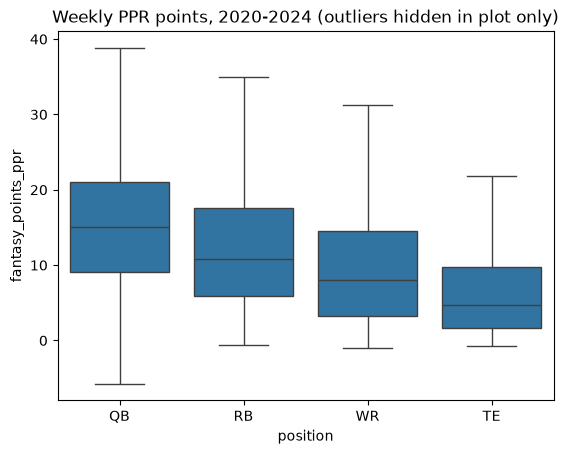

**What we see:** 18,402 player-weeks. Mean points range from 6.46 to 15.18; position changes both the typical score and its spread.

In [5]:
from IPython.display import Markdown
c_rows = player_weeks[player_weeks.season.isin(TRAIN_SEASONS)].copy()
c_summary = c_rows.groupby('position')[TARGET].agg(['count', 'mean', 'median', 'std']).reindex(POSITIONS)
display(c_summary.round(2))
sns.boxplot(data=c_rows, x='position', y=TARGET, order=POSITIONS, showfliers=False)
plt.title('Weekly PPR points, 2020-2024 (outliers hidden in plot only)')
plt.show()
display(Markdown(f"**What we see:** {len(c_rows):,} player-weeks. Mean points range from {c_summary['mean'].min():.2f} to {c_summary['mean'].max():.2f}; position changes both the typical score and its spread."))

### 4.2 Stability and memory
Lags count games played, including the 2019 warm-up season. They cross byes and season boundaries. Correlations use pairwise complete rows, with sample counts shown. Prior-season scoring uses the preceding calendar season only.

position,QB,RB,TE,WR
history,,,,
lag1,2829,3293,4157,8123
lag2,2801,3278,4133,8043
lag3,2761,3261,4110,7967
lag4,2710,3242,4088,7887
lag5,2659,3218,4062,7802
lag6,2607,3190,4036,7712
lag7,2557,3157,4006,7615
lag8,2511,3122,3970,7521
prior_season,2503,2935,3780,6974


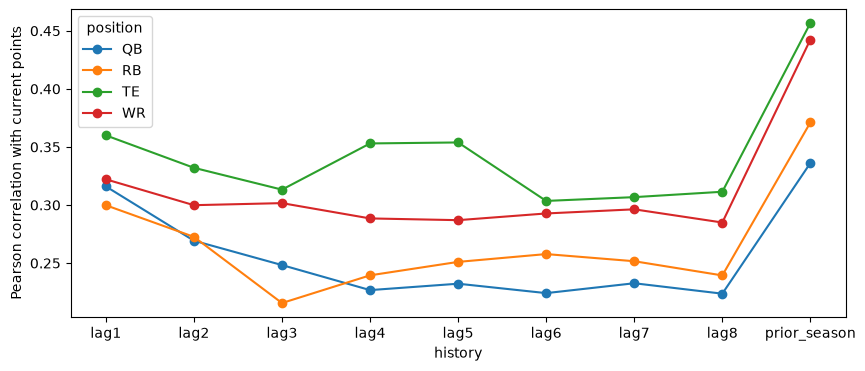

,offense_pct,targets,carries
position,,,
QB,0.411,0.554,0.492
RB,0.475,0.268,0.477
TE,0.615,0.443,0.680
WR,0.554,0.398,0.423


**What we see:** last-game point correlations range from 0.300 to 0.360. Usage stability differs by position; undefined values indicate constant usage. These correlations describe memory but do not select a half-life. Section 5's CV comparison selected 8 games.

In [6]:
c_hist = player_games[player_games.season < TEST_SEASON].sort_values(KEY).copy()
c_hist = c_hist[~c_hist.data_error].copy()
for lag in range(1, 9):
    c_hist[f'lag{lag}'] = c_hist.groupby('gsis_id')[TARGET].shift(lag)
for stat in ['offense_pct', 'targets', 'carries']:
    c_hist[f'{stat}_prior'] = c_hist.groupby('gsis_id')[stat].shift(1)
c_prior = c_hist.groupby(['gsis_id', 'season'])[TARGET].mean().rename('prior_season').reset_index()
c_prior['season'] += 1
c_lags = c_rows[KEY + ['position', TARGET]].merge(
    c_hist[KEY + [f'lag{i}' for i in range(1, 9)] + ['offense_pct', 'targets', 'carries'] +
           [f'{s}_prior' for s in ['offense_pct', 'targets', 'carries']]], on=KEY, validate='one_to_one').merge(c_prior, on=['gsis_id','season'], how='left')
c_memory = pd.DataFrame([
    {'position': p, 'history': h, 'n': len(w.dropna(subset=[h, TARGET])), 'correlation': w[h].corr(w[TARGET])}
    for p,w in c_lags.groupby('position') for h in [f'lag{i}' for i in range(1,9)] + ['prior_season']])
display(c_memory.pivot(index='history', columns='position', values='n'))
c_memory.pivot(index='history', columns='position', values='correlation').reindex(
    [f'lag{i}' for i in range(1,9)] + ['prior_season']).plot(marker='o', figsize=(10,4), ylabel='Pearson correlation with current points')
plt.show()
c_stability = pd.DataFrame({s: c_lags.groupby('position').apply(lambda w: w[s].corr(w[f'{s}_prior']))
                            for s in ['offense_pct','targets','carries']})
display(c_stability.round(3))
display(Markdown(f"**What we see:** last-game point correlations range from {c_memory.query('history == \"lag1\"').correlation.min():.3f} to {c_memory.query('history == \"lag1\"').correlation.max():.3f}. Usage stability differs by position; undefined values indicate constant usage. These correlations describe memory but do not select a half-life. Section 5's CV comparison selected 8 games."))

### 4.3 Early weeks and season drift
Compare within position so changes in the player mix do not dominate. Early means weeks 1-4. Counts and spread help distinguish drift from changes in sample composition.

count   mean   std
position period                       
QB       weeks 1-4    658  15.66  8.76
         weeks 5+    2171  15.04  8.81
RB       weeks 1-4    796  12.07  8.64
         weeks 5+    2497  12.42  8.48
TE       weeks 1-4   1025   5.88  6.14
         weeks 5+    3132   6.65  6.54
WR       weeks 1-4   1945   9.78  8.33
         weeks 5+    6178   9.74  8.22

count   mean   std
season position                    
2020   QB          532  16.86  9.16
       RB          610  12.29  8.90
       TE          799   6.59  6.53
       WR         1531  10.54  8.41
2021   QB          571  15.13  8.81
       RB          658  12.36  8.65
       TE          829   6.72  6.57
       WR         1665   9.65  8.14
2022   QB          555  14.86  8.41
       RB          695  12.05  8.52
       TE          859   6.05  6.34
       WR         1617   9.49  8.08
2023   QB          588  14.23  8.56
       RB          694  11.92  8.23
       TE          795   6.53  6.30
       WR         1632   9.58  8.31
2024   QB          583  14.97  8.90
       RB          636  13.11  8.30
       TE          875   6.44  6.49
       WR         1678   9.54  8.25

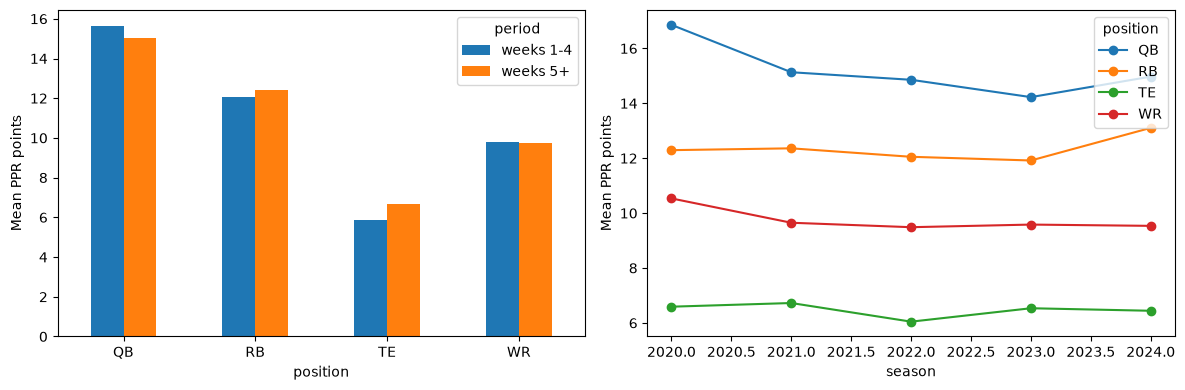

**What we see:** early-minus-later scoring ranges from -0.77 to 0.62 points across positions. Season means are descriptive: roster mix and schedule length also change. Training-window choices still require time-ordered CV.

In [7]:
c_rows['period'] = np.where(c_rows.week <= EARLY_SEASON_WEEKS, 'weeks 1-4', 'weeks 5+')
c_period = c_rows.groupby(['position','period'])[TARGET].agg(['count','mean','std'])
display(c_period.round(2))
c_seasons = c_rows.groupby(['season','position'])[TARGET].agg(['count','mean','std'])
display(c_seasons.round(2))
fig, axes = plt.subplots(1,2,figsize=(12,4))
c_period['mean'].unstack().plot.bar(ax=axes[0], ylabel='Mean PPR points', rot=0)
c_seasons['mean'].unstack().plot(marker='o',ax=axes[1],ylabel='Mean PPR points')
plt.tight_layout(); plt.show()
c_gap = c_period['mean'].unstack()['weeks 1-4'] - c_period['mean'].unstack()['weeks 5+']
display(Markdown(f"**What we see:** early-minus-later scoring ranges from {c_gap.min():.2f} to {c_gap.max():.2f} points across positions. Season means are descriptive: roster mix and schedule length also change. Training-window choices still require time-ordered CV."))

### 4.4 Vegas expectations and production
Use pre-game lines, separately within position. Team implied points are half the game total plus half the spread from the team's perspective.

,total_line,team_favored_by,implied_team_points
position,,,
QB,0.244,0.208,0.313
RB,0.070,0.076,0.103
TE,0.076,0.111,0.136
WR,0.112,0.087,0.136


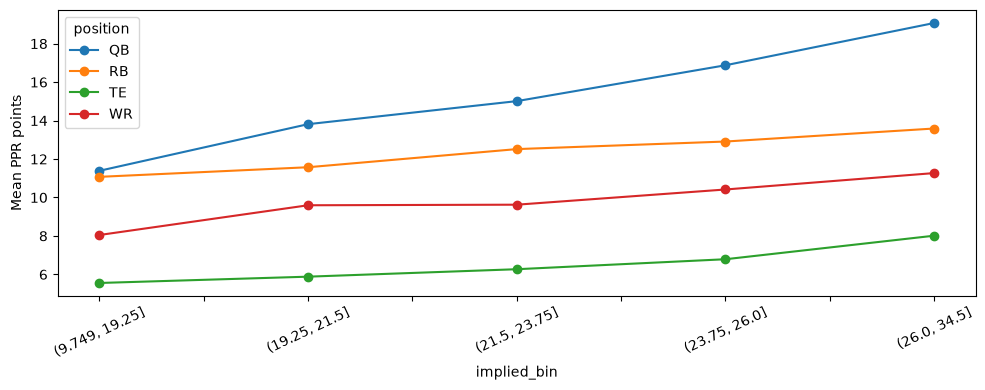

**What we see:** within-position correlations with implied team points range from 0.103 to 0.313. Lines summarize team scoring expectations; individual usage still matters.

In [8]:
c_rows['implied_team_points'] = (c_rows.total_line + c_rows.team_favored_by) / 2
c_vegas = pd.DataFrame({s:c_rows.groupby('position').apply(lambda w:w[s].corr(w[TARGET]))
                       for s in ['total_line','team_favored_by','implied_team_points']})
display(c_vegas.round(3))
c_rows['implied_bin'] = pd.qcut(c_rows.implied_team_points, 5, duplicates='drop')
c_rows.groupby(['implied_bin','position'], observed=True)[TARGET].mean().unstack().plot(marker='o',figsize=(10,4),ylabel='Mean PPR points')
plt.xticks(rotation=25); plt.tight_layout(); plt.show()
display(Markdown(f"**What we see:** within-position correlations with implied team points range from {c_vegas.implied_team_points.min():.3f} to {c_vegas.implied_team_points.max():.3f}. Lines summarize team scoring expectations; individual usage still matters."))

### 4.5 Expert benchmark on matching players
Inner-join only pre-game snapshots in training seasons. Ranks and top-12 sets are recomputed within each matched position-week. This is a restricted pool comparison, not accuracy over every NFL player. Small groups use the shared denominator of 12.

,spearman,top12_hit_rate
position,,
QB,0.440,0.605
RB,0.466,0.553
WR,0.549,0.368
TE,0.581,0.548


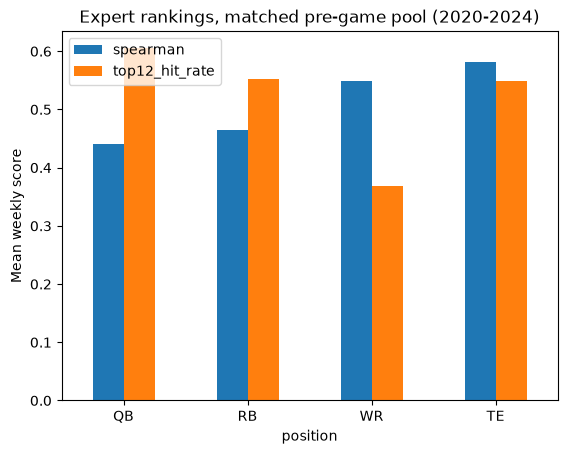

**What we see:** 13,839 matched player-weeks across 74 weeks. Expert mean weekly Spearman is 0.509; top-12 hit rate is 0.519. Missing snapshots and games played before snapshots are excluded.

In [9]:
c_experts = c_rows.merge(ecr_weekly.loc[~ecr_weekly.played_before_snapshot, KEY + ['ecr_pos_rank']], on=KEY, validate='one_to_one')
def c_expert_metrics(w):
    actual = w[TARGET].rank(ascending=False)
    expert = w.ecr_pos_rank.rank()
    return pd.Series({'spearman': expert.corr(actual, method='spearman'),
                      'top12_hit_rate': len(set(w.nsmallest(TOP_N,'ecr_pos_rank').index) & set(w.nlargest(TOP_N,TARGET).index))/TOP_N,
                      'players':len(w)})
c_ecr_weekly = c_experts.groupby(['season','week','position']).apply(c_expert_metrics)
c_ecr_summary = c_ecr_weekly.groupby('position')[['spearman','top12_hit_rate']].mean().reindex(POSITIONS)
display(c_ecr_summary.round(3))
c_ecr_summary.plot.bar(rot=0, ylabel='Mean weekly score', title='Expert rankings, matched pre-game pool (2020-2024)')
plt.show()
display(Markdown(f"**What we see:** {len(c_experts):,} matched player-weeks across {c_experts[['season','week']].drop_duplicates().shape[0]} weeks. Expert mean weekly Spearman is {c_ecr_weekly.spearman.mean():.3f}; top-12 hit rate is {c_ecr_weekly.top12_hit_rate.mean():.3f}. Missing snapshots and games played before snapshots are excluded."))